# PSO séquentiel (CPU) et massivement parallèle (CUDA) — lancement sur Kaggle
Projet M2 *Massively Parallel PSO and DE algorithms* (UHA).

**Fichiers (noms inchangés)** : `kernel.h`, `kernel.cu`, `kernel.cpp`, `main.cpp`. Une seule base de code, deux exécutables :
* `pso` : version parallèle GPU (`nvcc main.cpp kernel.cpp kernel.cu`)
* `pso_seq` : version séquentielle CPU, 1 thread (`g++ -DSEQUENTIAL main.cpp kernel.cpp`)

**Protocole** : Rastrigin, Rosenbrock, Griewank, Sphere (+ Lévy en option) ; D ∈ {10, 50, 100} ; P ∈ {50, 100, 500} ; MaxFEs = 10⁴·D ; 10 runs. Même algorithme, mêmes paramètres et même format de sortie pour les deux versions : accélération = temps CPU / temps GPU.

**Avant de lancer** : *Settings → Accelerator → GPU (T4 ou P100)*. Pour utiliser vos propres fichiers, ajoutez-les en *Dataset* (ils sont détectés dans `/kaggle/input`) ou déposez-les dans `/kaggle/working`.

## 1. Vérification du GPU et de nvcc

In [1]:
!nvidia-smi
!nvcc --version

Tue Oct 13 20:22:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Fichiers sources
Si un fichier du même nom existe déjà dans le dossier de travail, il est utilisé tel quel (aucun écrasement).

In [2]:
# Écrit les 4 fichiers sources UNIQUEMENT s'ils n'existent pas déjà dans le dossier de travail.
# -> vos propres fichiers (téléversés, ou copiés depuis /kaggle/input) sont toujours prioritaires.
import os, glob, shutil
FORCE_EMBEDDED = False      # True : écraser avec les versions embarquées ci-dessous
NAMES = ['kernel.h', 'kernel.cu', 'kernel.cpp', 'main.cpp']
SOURCES = {}
SOURCES['kernel.h'] = r'''#pragma once
// ============================================================================
//  Massively parallel PSO (CUDA) - benchmark protocol of the M2 project
//  Objective functions : see bench_info() / fitness() below
// ============================================================================
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <string>
#include <vector>

#ifdef __CUDACC__
  #define HD __host__ __device__
#else
  #define HD
#endif

// Precision of the swarm state. The fitness is ALWAYS accumulated in double
// (needed to reach errors ~1e-8 around biases such as -450).
// Compile with -DUSE_FLOAT for a pure single-precision swarm.
#ifdef USE_FLOAT
typedef float  real;
#else
typedef double real;
#endif

// ---------------------------------------------------------------------------
// Objective functions (same numbering as the original code)
//   0 : Levy                  (extra, not in the official protocol)
//   1 : Shifted Rastrigin     [-5, 5]^D        f* = -330
//   2 : Shifted Rosenbrock    [-100, 100]^D    f* =  390
//   3 : Shifted Griewank      [-600, 600]^D    f* = -180
//   4 : Shifted Sphere        [-100, 100]^D    f* = -450
// ---------------------------------------------------------------------------
enum ObjFunc { F_LEVY = 0, F_RASTRIGIN = 1, F_ROSENBROCK = 2, F_GRIEWANK = 3, F_SPHERE = 4 };

HD inline double f_bias(int func)
{
    switch (func) {
        case F_RASTRIGIN:  return -330.0;
        case F_ROSENBROCK: return  390.0;
        case F_GRIEWANK:   return -180.0;
        case F_SPHERE:     return -450.0;
        default:           return 0.0;
    }
}

// x[k * stride] is the k-th coordinate (stride = 1 on the host, stride = P on
// the GPU because the swarm is stored coordinate-major for coalesced access).
// o = shift vector (ignored by Levy).  One single implementation for CPU+GPU.
HD inline double fitness(const real* x, int stride, int D, int func, const real* o)
{
    const double PI = 3.14159265358979323846;
    double res = 0.0;

    switch (func) {
    case F_LEVY: {
        double w1 = 1.0 + ((double)x[0] - 1.0) / 4.0;
        double s  = sin(PI * w1);
        res = s * s;
        for (int i = 0; i < D - 1; i++) {
            double wi = 1.0 + ((double)x[i * stride] - 1.0) / 4.0;
            double t  = sin(PI * wi + 1.0);
            res += (wi - 1.0) * (wi - 1.0) * (1.0 + 10.0 * t * t);
        }
        double wd = 1.0 + ((double)x[(D - 1) * stride] - 1.0) / 4.0;
        double sd = sin(2.0 * PI * wd);
        res += (wd - 1.0) * (wd - 1.0) * (1.0 + sd * sd);
        break;
    }
    case F_RASTRIGIN: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z - 10.0 * cos(2.0 * PI * z) + 10.0;
        }
        break;
    }
    case F_ROSENBROCK: {
        for (int i = 0; i < D - 1; i++) {
            double zi  = (double)x[i * stride]       - (double)o[i]     + 1.0;
            double zi1 = (double)x[(i + 1) * stride] - (double)o[i + 1] + 1.0;
            double a = zi * zi - zi1;
            double b = zi - 1.0;
            res += 100.0 * a * a + b * b;
        }
        break;
    }
    case F_GRIEWANK: {
        double sum = 0.0, prod = 1.0;          // prod MUST start at 1 (was 0 in v1)
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            sum  += z * z / 4000.0;
            prod *= cos(z / sqrt((double)(i + 1)));
        }
        res = sum - prod + 1.0;
        break;
    }
    case F_SPHERE: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z;
        }
        break;
    }
    }
    return res + f_bias(func);
}

// ---------------------------------------------------------------------------
// Host-side helpers (kernel.cpp)
// ---------------------------------------------------------------------------
struct BenchInfo { const char* name; double lo, hi, bias; };
BenchInfo bench_info(int func);

// mode : "zero" | "rand" | "file:<path>"   (file = CEC2005 shift vector, first D values)
bool   make_shift(int func, int dim, const std::string& mode, std::vector<real>& o);
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o);

// ---------------------------------------------------------------------------
// PSO (kernel.cu)
// ---------------------------------------------------------------------------
struct PSOParams {
    int       func   = F_SPHERE;
    int       dim    = 10;
    int       pop    = 50;                 // 2 .. 1024
    long long maxFE  = 100000;             // protocol : 10^4 * dim
    double    wMax   = 0.9, wMin = 0.4;    // inertia, linearly decreasing
    double    c1     = 2.0,  c2   = 2.0;
    double    vmaxFrac = 0.2;              // |v| <= vmaxFrac * (hi - lo)
    unsigned long long seed = 1234ULL;
};

struct PSOResult {
    double            bestFit = 0.0;
    double            timeMs  = 0.0;       // GPU time measured with cudaEvent
    long long         fe      = 0;         // function evaluations really used
    int               iters   = 0;
    std::vector<real> gBest;
};

PSOResult cuda_pso(const PSOParams& prm, const std::vector<real>& shift);   // kernel.cu (GPU)
PSOResult seq_pso (const PSOParams& prm, const std::vector<real>& shift);   // pso_seq.cpp (CPU, 1 thread)
'''
SOURCES['kernel.cu'] = r'''#include <cuda_runtime.h>
#include <curand_kernel.h>
#include "kernel.h"

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t e_ = (call);                                                \
        if (e_ != cudaSuccess) {                                                \
            fprintf(stderr, "CUDA error %s:%d : %s\n", __FILE__, __LINE__,      \
                    cudaGetErrorString(e_));                                    \
            exit(1);                                                            \
        }                                                                       \
    } while (0)

#define INF_FIT 1.0e300
static const int TPB = 128;                       // threads per block

typedef curandStatePhilox4_32_10_t RngState;

// Swarm layout is coordinate-major (SoA): element (particle p, dim d) lives at
// d * P + p  ->  one thread per particle gives fully coalesced accesses.

__device__ __forceinline__ real urand(RngState* s)
{
#ifdef USE_FLOAT
    return curand_uniform(s);
#else
    return curand_uniform_double(s);
#endif
}

// ---- 1. initialisation : one thread per (particle, dimension) --------------
__global__ void k_init(real* pos, real* vel, real* pbest, double* pfit,
                       RngState* rng, int P, int D, real lo, real hi,
                       unsigned long long seed)
{
    int e = blockIdx.x * blockDim.x + threadIdx.x;
    if (e >= P * D) return;

    RngState st;
    curand_init(seed, (unsigned long long)e, 0ULL, &st);
    real x = lo + (hi - lo) * urand(&st);
    pos[e]   = x;
    pbest[e] = x;
    vel[e]   = (real)0;
    rng[e]   = st;
    if (e < P) pfit[e] = INF_FIT;
}

// ---- 2. velocity / position update : one thread per element ----------------
// independent r1, r2 for every particle AND every dimension (standard PSO)
__global__ void k_update(real* pos, real* vel, const real* pbest,
                         const real* gbest, RngState* rng, int P, int D,
                         real lo, real hi, real w, real c1, real c2, real vmax)
{
    int e = blockIdx.x * blockDim.x + threadIdx.x;
    if (e >= P * D) return;
    int d = e / P;

    RngState st = rng[e];
    real r1 = urand(&st);
    real r2 = urand(&st);
    rng[e] = st;

    real x = pos[e];
    real v = w * vel[e] + c1 * r1 * (pbest[e] - x) + c2 * r2 * (gbest[d] - x);
    v = fmax(-vmax, fmin(vmax, v));               // velocity clamping
    x += v;
    if (x < lo)      { x = lo; v = (real)0; }     // position clamping
    else if (x > hi) { x = hi; v = (real)0; }
    vel[e] = v;
    pos[e] = x;
}

// ---- 3. evaluation + pBest update : one thread per particle ----------------
// pBest fitness is stored (pfit) -> never recomputed.
__global__ void k_eval(const real* pos, real* pbest, double* pfit, int P, int D,
                       int func, const real* shift)
{
    int p = blockIdx.x * blockDim.x + threadIdx.x;
    if (p >= P) return;

    double f = fitness(pos + p, P, D, func, shift);
    if (f < pfit[p]) {
        pfit[p] = f;
        for (int d = 0; d < D; d++) pbest[(size_t)d * P + p] = pos[(size_t)d * P + p];
    }
}

// ---- 4. gBest : argmin reduction over pBest fitness, entirely on the GPU ----
// launched with ONE block whose size is a power of two >= P (P <= 1024)
__global__ void k_gbest(const real* pbest, const double* pfit, real* gbest,
                        double* gfit, int P, int D)
{
    __shared__ double sv[1024];
    __shared__ int    si[1024];
    int t = threadIdx.x;

    sv[t] = (t < P) ? pfit[t] : INF_FIT;
    si[t] = t;
    __syncthreads();

    for (int s = blockDim.x >> 1; s > 0; s >>= 1) {
        if (t < s && sv[t + s] < sv[t]) { sv[t] = sv[t + s]; si[t] = si[t + s]; }
        __syncthreads();
    }

    const double best = sv[0];
    const int    bi   = si[0];
    const double old  = *gfit;       // read by everybody BEFORE thread 0 writes
    __syncthreads();

    if (best < old) {
        for (int d = t; d < D; d += blockDim.x) gbest[d] = pbest[(size_t)d * P + bi];
        if (t == 0) *gfit = best;
    }
}

// ---------------------------------------------------------------------------
PSOResult cuda_pso(const PSOParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 2 || P > 1024 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "cuda_pso: invalid parameters (pop in [2,1024], dim>=1)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const size_t n = (size_t)P * D;

    static bool warm = false;
    if (!warm) { CUDA_CHECK(cudaFree(0)); warm = true; }   // create context

    real *d_pos, *d_vel, *d_pbest, *d_gbest, *d_shift;
    double *d_pfit, *d_gfit;
    RngState* d_rng;
    CUDA_CHECK(cudaMalloc(&d_pos,   n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_vel,   n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_pbest, n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_gbest, D * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_shift, D * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_pfit,  P * sizeof(double)));
    CUDA_CHECK(cudaMalloc(&d_gfit,  sizeof(double)));
    CUDA_CHECK(cudaMalloc(&d_rng,   n * sizeof(RngState)));

    CUDA_CHECK(cudaMemcpy(d_shift, shift.data(), D * sizeof(real), cudaMemcpyHostToDevice));
    const double inf = INF_FIT;
    CUDA_CHECK(cudaMemcpy(d_gfit, &inf, sizeof(double), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemset(d_gbest, 0, D * sizeof(real)));

    const int blocksE = (int)((n + TPB - 1) / TPB);
    const int blocksP = (P + TPB - 1) / TPB;
    int gbThreads = 32;
    while (gbThreads < P) gbThreads <<= 1;

    const real lo   = (real)bi.lo, hi = (real)bi.hi;
    const real vmax = (real)(prm.vmaxFrac * (bi.hi - bi.lo));

    // FE budget : initial evaluation (P) + nIter * P  <=  maxFE
    long long nIter = prm.maxFE / P - 1;
    if (nIter < 0) nIter = 0;

    cudaEvent_t e0, e1;
    CUDA_CHECK(cudaEventCreate(&e0));
    CUDA_CHECK(cudaEventCreate(&e1));
    CUDA_CHECK(cudaEventRecord(e0));

    k_init<<<blocksE, TPB>>>(d_pos, d_vel, d_pbest, d_pfit, d_rng, P, D, lo, hi, prm.seed);
    k_eval<<<blocksP, TPB>>>(d_pos, d_pbest, d_pfit, P, D, prm.func, d_shift);
    k_gbest<<<1, gbThreads>>>(d_pbest, d_pfit, d_gbest, d_gfit, P, D);

    for (long long it = 0; it < nIter; it++) {
        double w = (nIter > 1) ? prm.wMax - (prm.wMax - prm.wMin) * (double)it / (double)(nIter - 1)
                               : prm.wMax;
        k_update<<<blocksE, TPB>>>(d_pos, d_vel, d_pbest, d_gbest, d_rng, P, D, lo, hi,
                                   (real)w, (real)prm.c1, (real)prm.c2, vmax);
        k_eval<<<blocksP, TPB>>>(d_pos, d_pbest, d_pfit, P, D, prm.func, d_shift);
        k_gbest<<<1, gbThreads>>>(d_pbest, d_pfit, d_gbest, d_gfit, P, D);
    }
    CUDA_CHECK(cudaGetLastError());

    CUDA_CHECK(cudaEventRecord(e1));
    CUDA_CHECK(cudaEventSynchronize(e1));        // also surfaces async kernel errors
    float ms = 0.f;
    CUDA_CHECK(cudaEventElapsedTime(&ms, e0, e1));

    PSOResult r;
    r.gBest.resize(D);
    CUDA_CHECK(cudaMemcpy(r.gBest.data(), d_gbest, D * sizeof(real), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(&r.bestFit, d_gfit, sizeof(double), cudaMemcpyDeviceToHost));
    r.timeMs = ms;
    r.iters  = (int)nIter;
    r.fe     = (long long)P * (1 + nIter);

    cudaEventDestroy(e0); cudaEventDestroy(e1);
    cudaFree(d_pos); cudaFree(d_vel); cudaFree(d_pbest); cudaFree(d_gbest);
    cudaFree(d_shift); cudaFree(d_pfit); cudaFree(d_gfit); cudaFree(d_rng);
    return r;
}
'''
SOURCES['kernel.cpp'] = r'''#include "kernel.h"
#include <chrono>
#include <fstream>
#include <random>

BenchInfo bench_info(int func)
{
    switch (func) {
        case F_LEVY:       return { "Levy",       -10.0,   10.0,    0.0 };
        case F_RASTRIGIN:  return { "Rastrigin",   -5.0,    5.0, -330.0 };
        case F_ROSENBROCK: return { "Rosenbrock", -100.0,  100.0,  390.0 };
        case F_GRIEWANK:   return { "Griewank",   -600.0,  600.0, -180.0 };
        case F_SPHERE:     return { "Sphere",     -100.0,  100.0, -450.0 };
        default:           return { "?", 0, 0, 0 };
    }
}

// Shift vector o :  z = x - o, optimum at x* = o, f(x*) = bias.
//  "zero"       : o = 0 (behaviour of the original code)
//  "rand"       : reproducible o_i in [0.8*lo, 0.8*hi] (fixed seed, prefix-stable in dim)
//  "file:<path>": first `dim` numbers of a CEC2005 data file (e.g. sphere_func_data.txt)
bool make_shift(int func, int dim, const std::string& mode, std::vector<real>& o)
{
    o.assign(dim, (real)0);
    if (func == F_LEVY || mode == "zero") return true;

    BenchInfo b = bench_info(func);
    if (mode == "rand") {
        std::mt19937_64 gen(20261027ULL + (unsigned)func);
        std::uniform_real_distribution<double> U(0.8 * b.lo, 0.8 * b.hi);
        for (int i = 0; i < dim; i++) o[i] = (real)U(gen);
        return true;
    }
    if (mode.rfind("file:", 0) == 0) {
        std::ifstream f(mode.substr(5));
        if (!f) { fprintf(stderr, "cannot open shift file %s\n", mode.c_str() + 5); return false; }
        double v;
        for (int i = 0; i < dim; i++) {
            if (!(f >> v)) { fprintf(stderr, "shift file has fewer than %d values\n", dim); return false; }
            o[i] = (real)v;
        }
        return true;
    }
    fprintf(stderr, "unknown shift mode '%s'\n", mode.c_str());
    return false;
}

// Same code as the GPU one (kernel.h) -> used to double-check the GPU result.
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o)
{
    return fitness(x.data(), 1, (int)x.size(), func, o.data());
}


// ============================================================================
//  Sequential PSO (CPU, 1 thread) - reference implementation, compiled with the
//  rest of kernel.cpp (build with -DSEQUENTIAL to use it from main.cpp).
//  Same algorithm, parameters, budget and output as the CUDA version (kernel.cu):
//    - synchronous PSO : gBest is updated once per generation, after all pBest
//    - independent r1, r2 per particle AND per dimension
//    - inertia decreasing linearly wMax -> wMin, velocity and position clamping
//    - FEs = P * (1 + nIter) <= MaxFEs
//  Only the RNG differs (mt19937_64 here, cuRAND Philox on the GPU): results are
//  statistically equivalent, not bit-identical.
//  Memory layout is particle-major (p*D + d), the cache-friendly one on a CPU.
// ============================================================================
PSOResult seq_pso(const PSOParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 2 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "seq_pso: invalid parameters (pop >= 2, dim >= 1)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const size_t n = (size_t)P * D;
    const real lo   = (real)bi.lo, hi = (real)bi.hi;
    const real vmax = (real)(prm.vmaxFrac * (bi.hi - bi.lo));
    const real c1 = (real)prm.c1, c2 = (real)prm.c2;

    long long nIter = prm.maxFE / P - 1;           // initial evaluation costs P FEs
    if (nIter < 0) nIter = 0;

    std::mt19937_64 gen(prm.seed);
    std::uniform_real_distribution<real> U01((real)0, (real)1);

    std::vector<real>   pos(n), vel(n, (real)0), pbest(n), gbest(D, (real)0);
    std::vector<double> pfit(P, 1.0e300);
    double gfit = 1.0e300;

    // evaluation + pBest update (kernel E on the GPU)
    auto evaluate = [&]() {
        for (int p = 0; p < P; p++) {
            double f = fitness(&pos[(size_t)p * D], 1, D, prm.func, shift.data());
            if (f < pfit[p]) {
                pfit[p] = f;
                for (int d = 0; d < D; d++) pbest[(size_t)p * D + d] = pos[(size_t)p * D + d];
            }
        }
    };
    // gBest = argmin of pBest fitness (kernel G on the GPU)
    auto reduce_gbest = [&]() {
        int b = 0;
        for (int p = 1; p < P; p++) if (pfit[p] < pfit[b]) b = p;
        if (pfit[b] < gfit) {
            gfit = pfit[b];
            for (int d = 0; d < D; d++) gbest[d] = pbest[(size_t)b * D + d];
        }
    };

    auto t0 = std::chrono::steady_clock::now();

    // initialisation (kernel I)
    for (size_t e = 0; e < n; e++) {
        pos[e]   = lo + (hi - lo) * U01(gen);
        pbest[e] = pos[e];
    }
    evaluate();
    reduce_gbest();

    // main loop
    for (long long it = 0; it < nIter; it++) {
        const real w = (real)((nIter > 1)
            ? prm.wMax - (prm.wMax - prm.wMin) * (double)it / (double)(nIter - 1)
            : prm.wMax);

        // velocity & position update (kernel U)
        for (int p = 0; p < P; p++) {
            for (int d = 0; d < D; d++) {
                const size_t e = (size_t)p * D + d;
                const real r1 = U01(gen), r2 = U01(gen);
                real x = pos[e];
                real v = w * vel[e] + c1 * r1 * (pbest[e] - x) + c2 * r2 * (gbest[d] - x);
                if (v >  vmax) v =  vmax;
                if (v < -vmax) v = -vmax;
                x += v;
                if (x < lo)      { x = lo; v = (real)0; }
                else if (x > hi) { x = hi; v = (real)0; }
                vel[e] = v;
                pos[e] = x;
            }
        }
        evaluate();
        reduce_gbest();
    }

    auto t1 = std::chrono::steady_clock::now();

    PSOResult r;
    r.bestFit = gfit;
    r.gBest   = gbest;
    r.timeMs  = std::chrono::duration<double, std::milli>(t1 - t0).count();
    r.iters   = (int)nIter;
    r.fe      = (long long)P * (1 + nIter);
    return r;
}
'''
SOURCES['main.cpp'] = r'''#include "kernel.h"
#include <algorithm>
#include <cmath>
#include <cstring>

#ifdef SEQUENTIAL
  #define RUN_PSO seq_pso
  static const char* IMPL = "sequential CPU (1 thread)";
#else
  #define RUN_PSO cuda_pso
  static const char* IMPL = "CUDA GPU";
#endif

static void usage(const char* p)
{
    printf(
        "Usage: %s [options]\n"
        "  --func  all | 0..4      0 Levy, 1 Rastrigin, 2 Rosenbrock, 3 Griewank, 4 Sphere\n"
        "                          (all = the 4 official benchmarks 4,1,2,3)   [all]\n"
        "  --dim   D               problem dimension                            [10]\n"
        "  --pop   P               population size (2..1024)                    [50]\n"
        "  --runs  R               independent runs                             [10]\n"
        "  --seed  S               base seed (run k uses S+k)                   [1234]\n"
        "  --shift zero|rand|file:PATH   shift vector o                         [rand]\n"
        "  --sweep                 official protocol: dim {10,50,100} x pop {50,100,500}\n"
        "  --out   FILE.csv        write every run (for Wilcoxon / Kruskal-Wallis)\n"
        "MaxFEs = 10^4 * dim.\n", p);
}

int main(int argc, char** argv)
{
    std::vector<int> funcs = { F_SPHERE, F_RASTRIGIN, F_ROSENBROCK, F_GRIEWANK };
    std::vector<int> dims = { 10 }, pops = { 50 };
    int runs = 10;
    unsigned long long seed = 1234ULL;
    std::string shiftMode = "rand";
    const char* outPath = nullptr;
    bool fileShift = false;

    for (int a = 1; a < argc; a++) {
        std::string s = argv[a];
        auto next = [&]() -> std::string {
            if (a + 1 >= argc) { usage(argv[0]); exit(1); }
            return argv[++a];
        };
        if (s == "--func") {
            std::string v = next();
            if (v != "all") funcs = { atoi(v.c_str()) };
        } else if (s == "--dim")   dims = { atoi(next().c_str()) };
        else if (s == "--pop")     pops = { atoi(next().c_str()) };
        else if (s == "--runs")    runs = atoi(next().c_str());
        else if (s == "--seed")    seed = strtoull(next().c_str(), nullptr, 10);
        else if (s == "--shift")   { shiftMode = next(); fileShift = shiftMode.rfind("file:", 0) == 0; }
        else if (s == "--sweep")   { dims = { 10, 50, 100 }; pops = { 50, 100, 500 }; }
        else if (s == "--out")     outPath = argv[++a];
        else { usage(argv[0]); return 1; }
    }
    if (fileShift && funcs.size() != 1) {
        fprintf(stderr, "--shift file:... requires a single --func\n");
        return 1;
    }
    for (int f : funcs) if (f < 0 || f > 4) { fprintf(stderr, "bad --func\n"); return 1; }
    for (int p : pops)  if (p < 2 || p > 1024) { fprintf(stderr, "--pop must be in [2,1024]\n"); return 1; }
    for (int d : dims)  if (d < 1) { fprintf(stderr, "--dim must be >= 1\n"); return 1; }

    FILE* csv = nullptr;
    if (outPath) {
        csv = fopen(outPath, "w");
        if (!csv) { perror("open --out"); return 1; }
        fprintf(csv, "func,dim,pop,run,seed,fe,best,error,time_ms\n");
    }

#ifndef SEQUENTIAL
    // warm-up (context creation + lazy module loading), discarded
    { PSOParams w; w.dim = 2; w.pop = 32; w.maxFE = 3200; std::vector<real> o(2, 0);
      (void)cuda_pso(w, o); }
#endif

    printf("Implementation : %s\n", IMPL);
    printf("%-10s %4s %4s %4s | %-14s %-14s %-14s %-14s | %10s\n",
           "function", "dim", "pop", "runs", "mean", "std", "best", "mean_error", "time_ms");

    int mismatches = 0;
    for (int func : funcs) {
        BenchInfo bi = bench_info(func);
        for (int dim : dims) {
            std::vector<real> o;
            if (!make_shift(func, dim, shiftMode, o)) return 1;
            for (int pop : pops) {
                PSOParams prm;
                prm.func = func; prm.dim = dim; prm.pop = pop;
                prm.maxFE = 10000LL * dim;                       // protocol

                std::vector<double> fit(runs);
                double tsum = 0.0;
                for (int r = 0; r < runs; r++) {
                    prm.seed = seed + (unsigned long long)r;
                    PSOResult res = RUN_PSO(prm, o);
                    fit[r] = res.bestFit;
                    tsum  += res.timeMs;

                    // consistency check GPU value <-> host recomputation
                    double hf = host_fitness(res.gBest, func, o);
                    if (std::fabs(hf - res.bestFit) > 1e-6 * (1.0 + std::fabs(hf))) mismatches++;

                    if (csv)
                        fprintf(csv, "%s,%d,%d,%d,%llu,%lld,%.12e,%.12e,%.3f\n", bi.name, dim, pop, r,
                                prm.seed, res.fe, res.bestFit, res.bestFit - bi.bias, res.timeMs);
                }
                double mean = 0.0;
                for (double v : fit) mean += v;
                mean /= runs;
                double var = 0.0;
                for (double v : fit) var += (v - mean) * (v - mean);
                double sd = runs > 1 ? std::sqrt(var / (runs - 1)) : 0.0;   // sample std
                double best = *std::min_element(fit.begin(), fit.end());

                printf("%-10s %4d %4d %4d | %-14.6e %-14.6e %-14.6e %-14.6e | %10.2f\n",
                       bi.name, dim, pop, runs, mean, sd, best, mean - bi.bias, tsum / runs);
                fflush(stdout);
            }
        }
    }
    if (csv) fclose(csv);
    if (mismatches) printf("WARNING: %d run(s) with GPU/host fitness mismatch\n", mismatches);
    return 0;
}
'''

for n in NAMES:
    if os.path.exists(n) and not FORCE_EMBEDDED:
        print(f"{n:11s} : fichier existant utilisé")
        continue
    found = [] if FORCE_EMBEDDED else glob.glob(f"/kaggle/input/**/{n}", recursive=True)
    if found:
        shutil.copy(found[0], n); print(f"{n:11s} : copié depuis {found[0]}")
    else:
        open(n, "w").write(SOURCES[n]); print(f"{n:11s} : version embarquée écrite")


kernel.h    : copié depuis /kaggle/input/datasets/jesuisenfrance2024/pso-files/kernel.h
kernel.cu   : copié depuis /kaggle/input/datasets/jesuisenfrance2024/pso-files/kernel.cu
kernel.cpp  : copié depuis /kaggle/input/datasets/jesuisenfrance2024/pso-files/kernel.cpp
main.cpp    : copié depuis /kaggle/input/datasets/jesuisenfrance2024/pso-files/main.cpp


## 3. Compilation (GPU puis CPU)
L'architecture `sm_XX` est détectée automatiquement. Pour une swarm tout en float, ajouter `-DUSE_FLOAT` aux deux commandes.

In [3]:
import subprocess

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(r.stdout + r.stderr)
    return r.returncode

try:
    cc = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"]).decode().split()[0]
    ARCH = "sm_" + cc.replace(".", "")
except Exception:
    ARCH = "sm_75"
print("Architecture GPU :", ARCH)

rc = sh(f"nvcc -O3 -arch={ARCH} main.cpp kernel.cpp kernel.cu -o pso")
assert rc == 0, "Erreur de compilation GPU : lire le message ci-dessus"
rc = sh("g++ -O3 -std=c++14 -DSEQUENTIAL main.cpp kernel.cpp -o pso_seq")
assert rc == 0, "Erreur de compilation CPU : lire le message ci-dessus"
print("Compilation GPU + CPU OK")

Architecture GPU : sm_75


Compilation GPU + CPU OK


## 4. Test rapide (3 runs, D=10, P=50, les 4 fonctions)
Optima attendus : Sphere −450, Rastrigin −330, Rosenbrock 390, Griewank −180. Un avertissement `GPU/host fitness mismatch` signale une incohérence.

In [4]:
!./pso --func all --dim 10 --pop 50 --runs 3
!./pso_seq --func all --dim 10 --pop 50 --runs 3

Implementation : CUDA GPU
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       10   50    3 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |      40.27
Rastrigin    10   50    3 | -3.276784e+02  2.297760e+00   -3.290050e+02  2.321571e+00   |      60.58
Rosenbrock   10   50    3 | 3.932858e+02   3.142961e-01   3.929612e+02   3.285830e+00   |      21.39
Griewank     10   50    3 | -1.799213e+02  1.951564e-02   -1.799360e+02  7.870447e-02   |      44.98
Implementation : sequential CPU (1 thread)
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       10   50    3 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |      24.96
Rastrigin    10   50    3 | -3.280101e+02  1.723320e+00   -3.300000e+02  1.989918e+00   |      44.05
Rosenbrock   10   50    3 | 3.917021e+02   1.904012e+00   3.901274e+02   1.702062e+00   |      29.55
Griewank     10   50  

## 5. Configuration libre
Fonction : `all` ou 0 Lévy, 1 Rastrigin, 2 Rosenbrock, 3 Griewank, 4 Sphere. Décalage : `rand` (reproductible), `zero`, ou `file:CHEMIN` (fichier de données CEC2005, une seule fonction à la fois).

In [5]:
FUNC, DIM, POP, RUNS = "all", 50, 100, 10
SHIFT = "rand"      # "zero" | "rand" | "file:/chemin/vers/sphere_func_data.txt"
!./pso     --func {FUNC} --dim {DIM} --pop {POP} --runs {RUNS} --shift {SHIFT}
!./pso_seq --func {FUNC} --dim {DIM} --pop {POP} --runs {RUNS} --shift {SHIFT}

Implementation : CUDA GPU
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       50  100   10 | -3.282571e+02  1.960246e+02   -4.500000e+02  1.217429e+02   |      93.74
Rastrigin    50  100   10 | -2.546231e+02  2.235529e+01   -2.792571e+02  7.537694e+01   |     327.32
Rosenbrock   50  100   10 | 4.945362e+06   1.048933e+07   4.858754e+02   4.944972e+06   |     151.57
Griewank     50  100   10 | -1.771276e+02  4.875198e+00   -1.800000e+02  2.872449e+00   |     572.75
Implementation : sequential CPU (1 thread)
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       50  100   10 | -3.494850e+02  2.167583e+02   -4.500000e+02  1.005150e+02   |     609.72
Rastrigin    50  100   10 | -2.557139e+02  1.973281e+01   -2.872168e+02  7.428610e+01   |    1070.89
Rosenbrock   50  100   10 | 2.262491e+03   4.863716e+03   4.254361e+02   1.872491e+03   |     667.41
Griewank     50  100  

## 6. Protocole complet
4 fonctions × 3 dimensions × 3 populations × 10 runs, chaque run enregistré en CSV (utile pour Wilcoxon / Kruskal-Wallis). GPU : quelques minutes. CPU (1 cœur) : environ 5 à 15 min selon la machine.

In [6]:
%%time
!./pso --sweep --runs 10 --out results_pso.csv | tee summary_pso.txt

Implementation : CUDA GPU
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       10   50   10 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |      33.70
Sphere       10  100   10 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |       9.67
Sphere       10  500   10 | -4.500000e+02  2.029431e-06   -4.500000e+02  1.011040e-06   |       2.29
Sphere       50   50   10 | -1.680577e+02  6.294376e+02   -4.500000e+02  2.819423e+02   |     119.20
Sphere       50  100   10 | -3.282571e+02  1.960246e+02   -4.500000e+02  1.217429e+02   |      79.04
Sphere       50  500   10 | -4.499987e+02  1.095855e-03   -4.499997e+02  1.260016e-03   |      27.10
Sphere      100   50   10 | 1.568044e+03   1.265445e+03   6.928633e+01   2.018044e+03   |     338.12
Sphere      100  100   10 | 7.154004e+02   9.565978e+02   -4.500000e+02  1.165400e+03   |     298.18
Sphere      100  500   10 | -2.799071e+01  7.101555e+02   -4.4997

In [7]:
%%time
!./pso_seq --sweep --runs 10 --out results_pso_seq.csv | tee summary_pso_seq.txt

Implementation : sequential CPU (1 thread)
function    dim  pop runs | mean           std            best           mean_error     |    time_ms
Sphere       10   50   10 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |      25.10
Sphere       10  100   10 | -4.500000e+02  0.000000e+00   -4.500000e+02  0.000000e+00   |      26.02
Sphere       10  500   10 | -4.500000e+02  3.361324e-07   -4.500000e+02  3.635552e-07   |      25.48
Sphere       50   50   10 | -4.500000e+02  2.679624e-14   -4.500000e+02  1.136868e-13   |     583.10
Sphere       50  100   10 | -3.494850e+02  2.167583e+02   -4.500000e+02  1.005150e+02   |     587.57
Sphere       50  500   10 | -4.499991e+02  5.120290e-04   -4.499995e+02  9.336174e-04   |     601.97
Sphere      100   50   10 | 1.459675e+03   1.403449e+03   -4.500000e+02  1.909675e+03   |    2308.28
Sphere      100  100   10 | 2.223747e+03   3.436487e+03   -4.500000e+02  2.673747e+03   |    2394.89
Sphere      100  500   10 | 1.642440e+01   6.178

## 7. Analyse des résultats
### 7.1 Tableau récapitulatif (erreur = f − f*, succès si erreur < 1e-8)

In [8]:
import pandas as pd, numpy as np
from scipy import stats
pd.set_option("display.width", 200, "display.max_rows", 200)

df = pd.read_csv("results_pso.csv")
df["success"] = df["error"] < 1e-8
summary = (df.groupby(["func", "dim", "pop"])
             .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                  min_best=("best", "min"), mean_error=("error", "mean"),
                  std_error=("error", "std"), success_rate=("success", "mean"),
                  time_s=("time_ms", lambda s: s.mean() / 1000.0))
             .reset_index())
summary.to_csv("summary_pso.csv", index=False)
summary

,func,dim,pop,mean_best,std_best,min_best,mean_error,std_error,success_rate,time_s
0,Griewank,10,50,-1.799319e+02,1.316315e-02,-1.799435e+02,6.814665e-02,1.316315e-02,0.0,0.044837
1,Griewank,10,100,-1.799379e+02,3.284767e-02,-1.799901e+02,6.210389e-02,3.284767e-02,0.0,0.029219
2,Griewank,10,500,-1.798722e+02,9.162377e-02,-1.799718e+02,1.278375e-01,9.162377e-02,0.0,0.006165
3,Griewank,50,50,-1.754642e+02,4.149057e+00,-1.800000e+02,4.535830e+00,4.149057e+00,0.2,0.794355
4,Griewank,50,100,-1.771276e+02,4.875198e+00,-1.800000e+02,2.872449e+00,4.875198e+00,0.3,0.573569
5,Griewank,50,500,-1.788296e+02,3.682065e+00,-1.799994e+02,1.170353e+00,3.682065e+00,0.0,0.125819
6,Griewank,100,50,-1.371796e+02,3.492555e+01,-1.682800e+02,4.282043e+01,3.492555e+01,0.0,3.042755
7,Griewank,100,100,-1.668657e+02,7.716313e+00,-1.752990e+02,1.313429e+01,7.716313e+00,0.0,2.284304
8,Griewank,100,500,-1.697232e+02,1.301510e+01,-1.799568e+02,1.027676e+01,1.301510e+01,0.0,0.515561
9,Rastrigin,10,50,-3.281096e+02,1.441833e+00,-3.300000e+02,1.890422e+00,1.441833e+00,0.1,0.031936


### 7.2 Temps de calcul moyen 

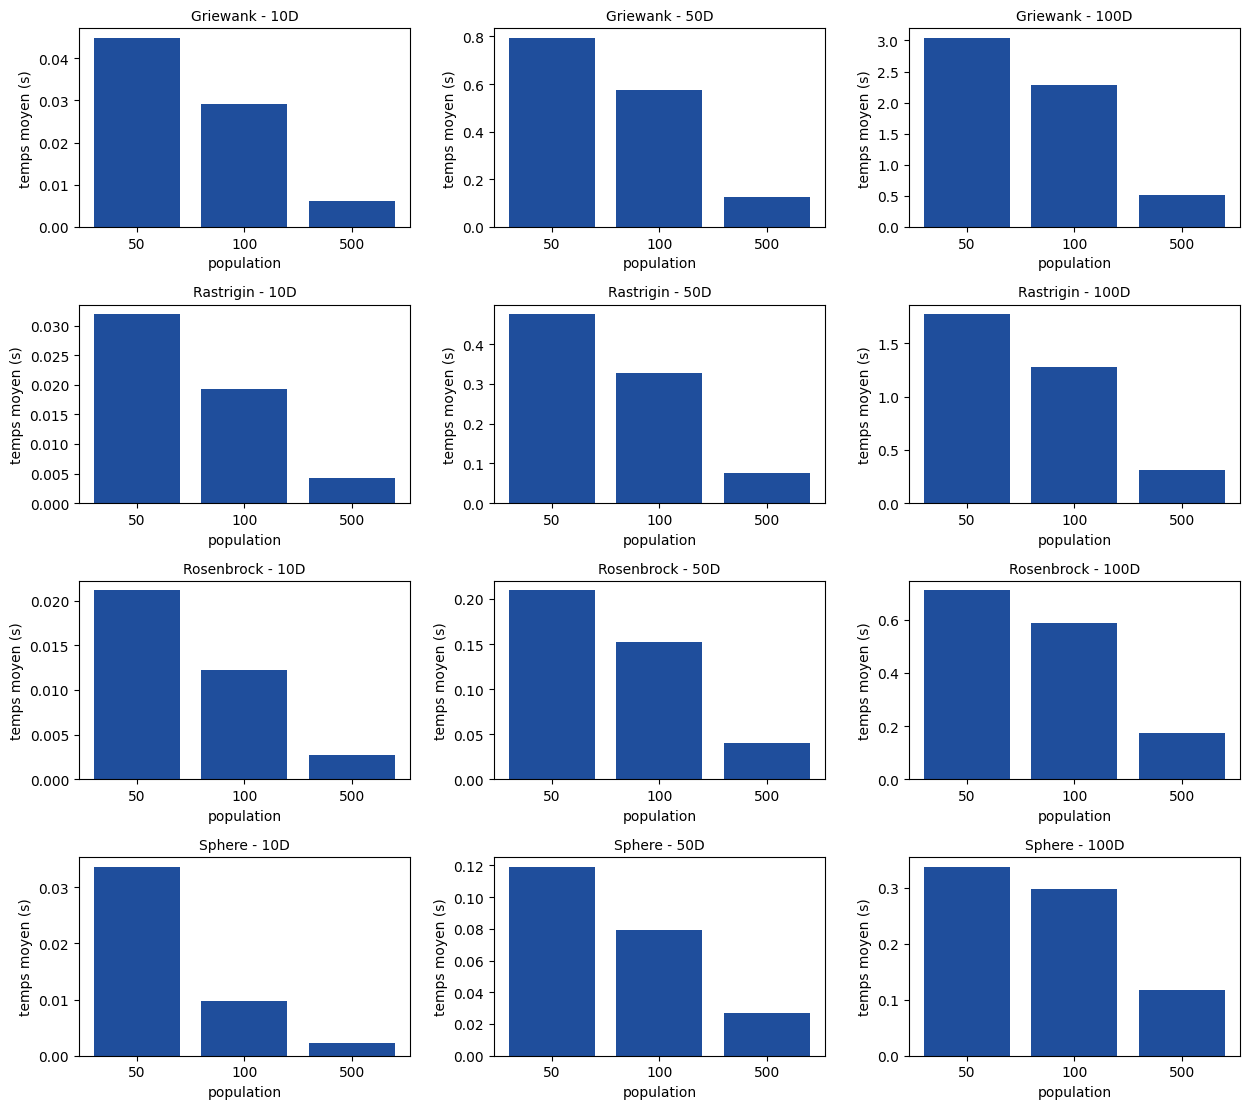

In [9]:
import matplotlib.pyplot as plt

funcs = list(summary["func"].unique())
dims = sorted(summary["dim"].unique())
pops = sorted(summary["pop"].unique())
fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.2 * len(dims), 2.8 * len(funcs)), squeeze=False)
for i, f in enumerate(funcs):
    for j, d in enumerate(dims):
        s = summary[(summary.func == f) & (summary.dim == d)].set_index("pop").reindex(pops)
        ax = axes[i][j]
        ax.bar([str(p) for p in pops], s["time_s"], color="#1f4e9c")
        ax.set_title(f"{f} - {d}D", fontsize=10)
        ax.set_xlabel("population"); ax.set_ylabel("temps moyen (s)")
plt.tight_layout()
plt.savefig("fig_time_vs_pop.png", dpi=200)
plt.show()

### 7.3 Qualité : erreur moyenne par population (échelle log)

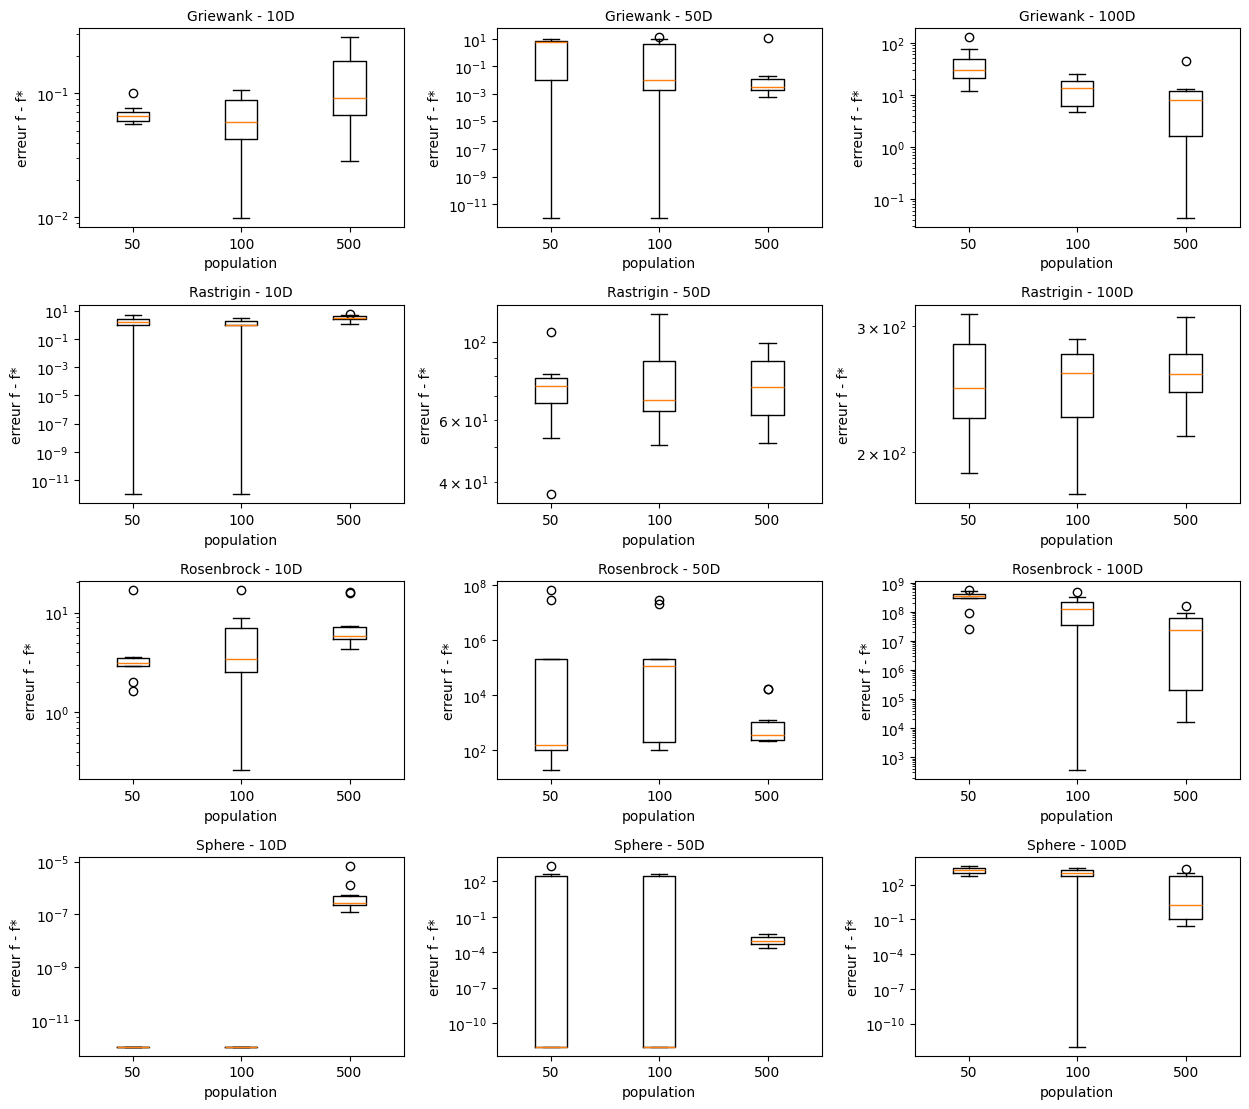

In [10]:
fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.2 * len(dims), 2.8 * len(funcs)), squeeze=False)
for i, f in enumerate(funcs):
    for j, d in enumerate(dims):
        ax = axes[i][j]
        data = [df[(df.func == f) & (df.dim == d) & (df["pop"] == p)]["error"].clip(lower=1e-12) for p in pops]
        ax.boxplot(data); ax.set_xticklabels([str(p) for p in pops])
        ax.set_yscale("log"); ax.set_title(f"{f} - {d}D", fontsize=10)
        ax.set_xlabel("population"); ax.set_ylabel("erreur f - f*")
plt.tight_layout()
plt.savefig("fig_error_boxplots.png", dpi=200)
plt.show()

### 7.4 Séquentiel contre parallèle : temps et accélération

,func,dim,pop,time_seq_s,time_gpu_s,speedup
0,Griewank,10,50,0.052144,0.044837,1.162957
1,Griewank,10,100,0.053032,0.029219,1.814952
2,Griewank,10,500,0.056611,0.006165,9.182362
3,Griewank,50,50,1.122097,0.794355,1.412590
4,Griewank,50,100,1.143507,0.573569,1.993668
5,Griewank,50,500,1.223012,0.125819,9.720431
6,Griewank,100,50,4.528027,3.042755,1.488134
7,Griewank,100,100,4.612428,2.284304,2.019184
8,Griewank,100,500,4.963029,0.515561,9.626458
9,Rastrigin,10,50,0.041033,0.031936,1.284841


Accélération moyenne par dimension :


,mean,min,max
dim,,,
10,4.488038,0.744761,11.135758
50,7.516845,1.412590,22.212182
100,7.557356,1.488134,20.557687


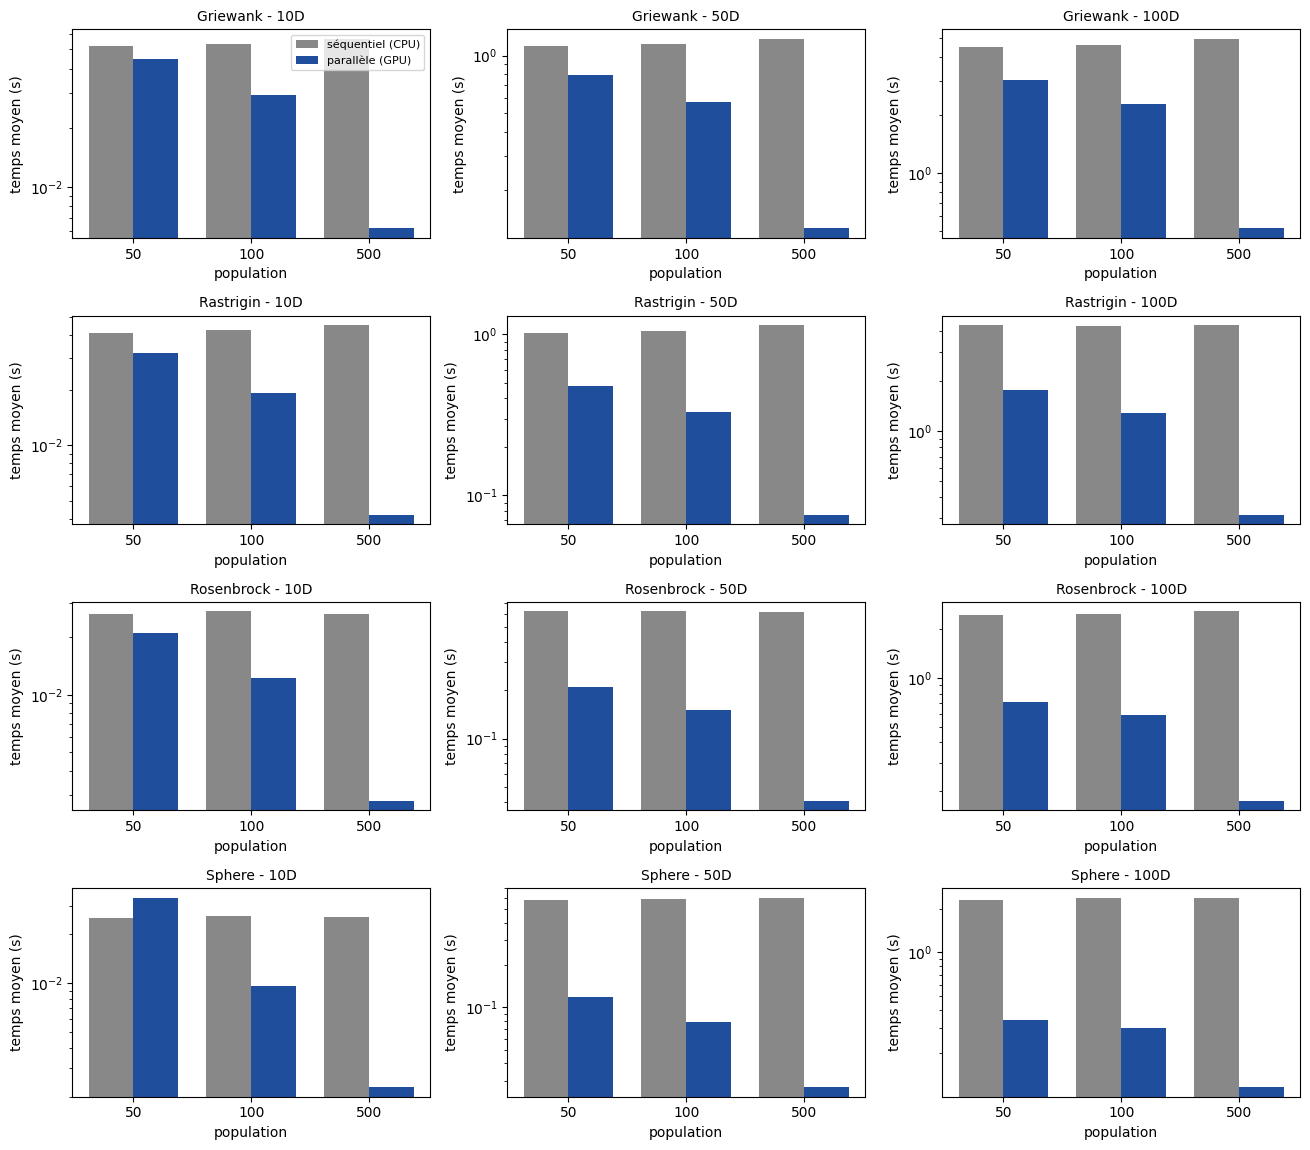

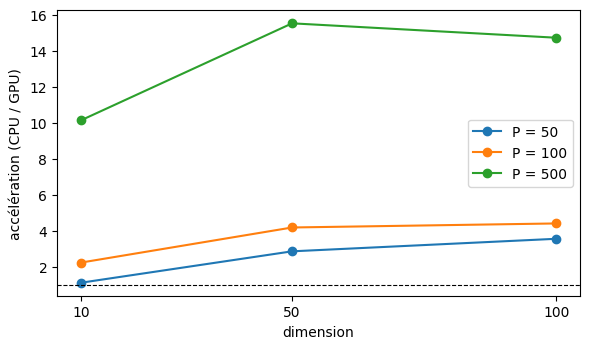

In [11]:
seq = pd.read_csv("results_pso_seq.csv")
s_seq = (seq.groupby(["func", "dim", "pop"])
            .agg(time_seq_s=("time_ms", lambda s: s.mean() / 1000.0),
                 mean_error_seq=("error", "mean"))
            .reset_index())
cmp = summary.merge(s_seq, on=["func", "dim", "pop"]).rename(columns={"time_s": "time_gpu_s"})
cmp["speedup"] = cmp["time_seq_s"] / cmp["time_gpu_s"]
cmp.to_csv("comparison_seq_gpu.csv", index=False)
display(cmp[["func", "dim", "pop", "time_seq_s", "time_gpu_s", "speedup"]])
print("Accélération moyenne par dimension :")
display(cmp.groupby("dim")["speedup"].agg(["mean", "min", "max"]))

fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.4 * len(dims), 2.9 * len(funcs)), squeeze=False)
xs = np.arange(len(pops)); wd = 0.38
for i, f in enumerate(funcs):
    for j, d in enumerate(dims):
        c = cmp[(cmp.func == f) & (cmp.dim == d)].set_index("pop").reindex(pops)
        ax = axes[i][j]
        ax.bar(xs - wd / 2, c["time_seq_s"], wd, label="séquentiel (CPU)", color="#888888")
        ax.bar(xs + wd / 2, c["time_gpu_s"], wd, label="parallèle (GPU)", color="#1f4e9c")
        ax.set_xticks(xs); ax.set_xticklabels([str(p) for p in pops])
        ax.set_yscale("log"); ax.set_title(f"{f} - {d}D", fontsize=10)
        ax.set_xlabel("population"); ax.set_ylabel("temps moyen (s)")
        if i == 0 and j == 0: ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig_time_seq_vs_gpu.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.6))
for p in pops:
    c = cmp[cmp["pop"] == p].groupby("dim")["speedup"].mean()
    ax.plot(c.index, c.values, marker="o", label=f"P = {p}")
ax.set_xlabel("dimension"); ax.set_ylabel("accélération (CPU / GPU)")
ax.axhline(1, color="k", lw=0.8, ls="--"); ax.set_xticks(dims); ax.legend()
plt.tight_layout()
plt.savefig("fig_speedup.png", dpi=200)
plt.show()

### 7.5 Les deux versions du PSO donnent-elles la même qualité ? (Wilcoxon / Mann-Whitney, CPU contre GPU)
Les générateurs aléatoires diffèrent (mt19937 contre cuRAND) : on attend une équivalence **statistique**, soit environ 5 % de tests « significatifs » dus au hasard.

In [12]:
rows = []
for (f, d, p), g in df.groupby(["func", "dim", "pop"]):
    o = seq[(seq.func == f) & (seq.dim == d) & (seq["pop"] == p)]
    if len(o) > 1 and len(g) > 1:
        try:
            u, pv = stats.mannwhitneyu(g["error"], o["error"], alternative="two-sided")
        except ValueError:
            pv = 1.0
        rows.append({"func": f, "dim": d, "pop": p, "mean_err_gpu": g["error"].mean(),
                     "mean_err_cpu": o["error"].mean(), "p_value": pv, "différent(0.05)": pv < 0.05})
eq = pd.DataFrame(rows)
display(eq)
print(f"{int(eq['différent(0.05)'].sum())} configurations significativement différentes sur {len(eq)}")

,func,dim,pop,mean_err_gpu,mean_err_cpu,p_value,différent(0.05)
0,Griewank,10,50,6.814665e-02,5.670188e-02,0.307489,False
1,Griewank,10,100,6.210389e-02,6.152580e-02,0.850107,False
2,Griewank,10,500,1.278375e-01,1.300674e-01,0.677585,False
3,Griewank,50,50,4.535830e+00,4.208770e+00,0.909450,False
4,Griewank,50,100,2.872449e+00,4.191915e+00,0.621599,False
5,Griewank,50,500,1.170353e+00,4.983420e-03,0.307489,False
6,Griewank,100,50,4.282043e+01,3.212043e+01,0.969850,False
7,Griewank,100,100,1.313429e+01,1.685250e+01,0.733730,False
8,Griewank,100,500,1.027676e+01,1.063603e+01,0.472676,False
9,Rastrigin,10,50,1.890422e+00,1.890422e+00,0.907296,False


0 configurations significativement différentes sur 36


### 7.6 Tests statistiques
* **Kruskal-Wallis** : l'effet de la taille de population sur l'erreur est-il significatif (par fonction et dimension) ?
* **Wilcoxon (somme des rangs / Mann-Whitney)** : PSO contre DE, si vous placez le CSV de votre DE (mêmes colonnes : `func,dim,pop,run,best,error`) dans `results_de.csv`.

In [13]:
from scipy import stats
import os

rows = []
for f in funcs:
    for d in dims:
        groups = [df[(df.func == f) & (df.dim == d) & (df["pop"] == p)]["error"].values for p in pops]
        if all(len(g) > 1 for g in groups) and not all(np.allclose(groups[0], g) for g in groups):
            h, p_val = stats.kruskal(*groups)
        else:
            h, p_val = np.nan, np.nan
        rows.append({"func": f, "dim": d, "H": h, "p_value": p_val, "significatif(0.05)": p_val < 0.05})
kw = pd.DataFrame(rows)
display(kw)

DE_CSV = "results_de.csv"
if os.path.exists(DE_CSV):
    de = pd.read_csv(DE_CSV)
    out = []
    for (f, d, p), g in df.groupby(["func", "dim", "pop"]):
        o = de[(de.func == f) & (de.dim == d) & (de["pop"] == p)]
        if len(o) > 1:
            u, pv = stats.mannwhitneyu(g["error"], o["error"], alternative="two-sided")
            out.append({"func": f, "dim": d, "pop": p, "mean_PSO": g["error"].mean(),
                        "mean_DE": o["error"].mean(), "p_value": pv,
                        "meilleur": "PSO" if g["error"].mean() < o["error"].mean() else "DE",
                        "significatif(0.05)": pv < 0.05})
    display(pd.DataFrame(out))
else:
    print("results_de.csv absent : comparaison PSO / DE ignorée.")

,func,dim,H,p_value,significatif(0.05)
0,Griewank,10,3.362581,0.186134,False
1,Griewank,50,1.777857,0.411096,False
2,Griewank,100,12.707097,0.001741,True
3,Rastrigin,10,12.153910,0.002295,True
4,Rastrigin,50,0.216774,0.897280,False
5,Rastrigin,100,0.289032,0.865441,False
6,Rosenbrock,10,8.162461,0.016887,True
7,Rosenbrock,50,1.040000,0.594521,False
8,Rosenbrock,100,12.482581,0.001947,True
9,Sphere,10,27.488152,0.000001,True


results_de.csv absent : comparaison PSO / DE ignorée.


## 8. Fichiers à récupérer
Tout est dans `/kaggle/working` (onglet *Output*) : `results_pso.csv`, `results_pso_seq.csv`, `summary_pso.csv`, `comparison_seq_gpu.csv` et les figures `fig_*.png`.